In [123]:
import numpy as np
import matplotlib.pyplot as plt

subspace_distance_high =1.1
subspace_distance_low =1e-1
num_endmembers =10
em_index = np.arange(1,num_endmembers+1)
bandcount =437
rho_threshold = 0.01 # minimum seperable reflectance difference
max_height = np.linalg.norm(np.ones((1,bandcount)))
endmember_seperability=rho_threshold*max_height
print(f"The maximum height is {max_height:.1f}")
print(f"A 1% reflectance difference is {endmember_seperability:.3f}")

# Define Orthogonal Subspace Distance Curve
subspace_distance_high =1.1
subspace_distance_low =1e-1
num_endmembers =10
em_index = np.arange(1,num_endmembers+1)
num_materials = 5

OSD= np.geomspace(subspace_distance_high,subspace_distance_low,num=num_endmembers)
OSD[num_materials:-1]= OSD[num_materials:-1]/5

The maximum height is 20.9
A 1% reflectance difference is 0.209


## sum is $ \displaystyle\sum^n_{k=1} h_k$
## product is $ Vol_n = h_1 - \displaystyle\prod^n_{k=3} h_k$
## kth root is $Vol_n = \displaystyle\prod^n_{k=2} \sqrt[k]{h_k}$

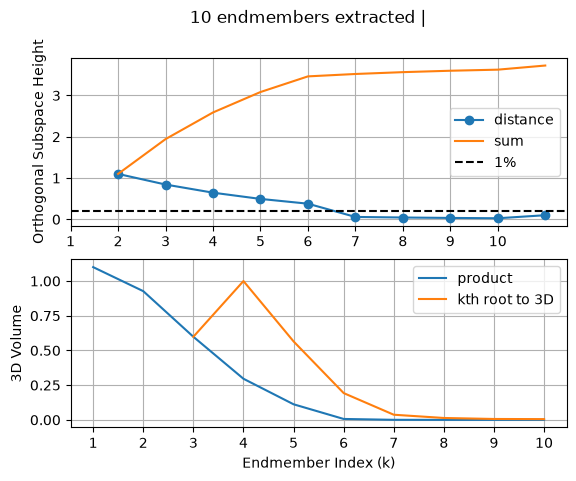

In [136]:
OSDsum = np.cumsum(OSD)
OSDprod = np.cumprod(OSD)

OSDprodnormalized = np.full(num_endmembers, np.nan)
OSDprod_3D = np.power(OSDprod, 3/em_index)  #OSDprod** 3/em_index     #
OSDprodnormalized[2] = OSDprod[2]
for i in range(3,len(OSDsum)):
    
    OSDprodnormalized[i]= OSDprod[i-1] + OSDprod_3D[i]


plt.subplots(2,1)
plt.subplot(2,1,1)
plt.plot(em_index+1,OSD, marker="o", label="distance")
plt.plot(em_index+1,OSDsum,label='sum')
plt.axhline(y=endmember_seperability,linestyle='--',color='black',label='1%')
plt.ylabel("Orthogonal Subspace Height")
plt.grid()
plt.xticks(em_index)
plt.legend(loc='best')
plt.subplot(2,1,2)
plt.plot(em_index,OSDprod,label="product")
plt.plot(em_index[2:],OSDprodnormalized[2:],label="kth root to 3D")
plt.ylabel("3D Volume")
#plt.plot(em_index+1,OSD[0]-log_volume_over_floor,label="height over threshold")
#plt.plot(em_index+1,volume_over_floor,label='Log-Volume Excess over Critical Floor')

plt.xlabel("Endmember Index (k)")
plt.xticks(em_index)
plt.legend(loc='best')
plt.suptitle(f"{num_endmembers} endmembers extracted | ")
plt.grid()
plt.show()

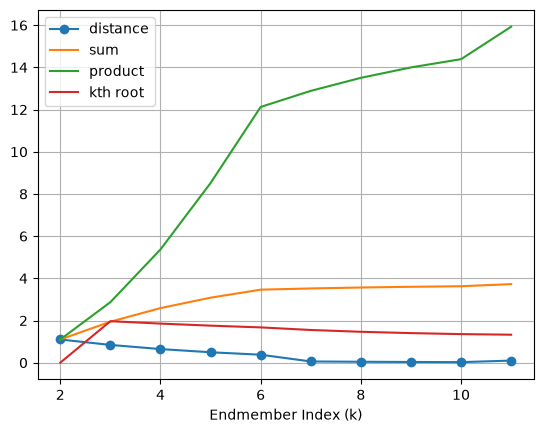

In [122]:
import numpy as np
import matplotlib.pyplot as plt


plus1= OSD+1
plus1prod = np.cumprod(plus1)
plus1prodnormalized = np.zeros(shape=np.shape(OSDprod))
for i in range(1,len(plus1prod)):
    plus1prodnormalized[i]=np.power(plus1prod[i],1/(i+1))

plt.plot(em_index+1,plus1-1, marker="o",label="distance")
plt.plot(em_index+1,OSDsum,label="sum")
plt.plot(em_index+1,plus1prod-1,label="product")
plt.plot(em_index+1,plus1prodnormalized,label="kth root")
plt.legend()
plt.grid()
plt.xlabel("Endmember Index (k)")
plt.show()